Train Set:16512
4128
16512
4128
       Actual  Prediction
1945    1.963    1.720693
18006   2.750    2.893637
13062   1.275    1.880470
13396   1.589    1.951685
9787    0.875    1.840110
0.5124717232649117
0.6055190474770135


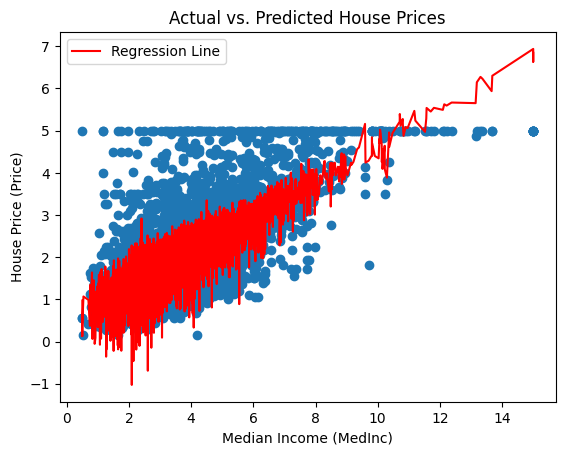

MedInc        0.688075
HouseAge      0.105623
AveRooms      0.151948
AveBedrms    -0.046701
Population   -0.024650
AveOccup     -0.023737
Latitude     -0.144160
Longitude    -0.045967
Price         1.000000
Name: Price, dtype: float64
MedInc        0.684923
HouseAge      0.101470
AveRooms      0.155458
AveBedrms    -0.073076
Population   -0.014121
AveOccup     -0.004534
Latitude     -0.131827
Longitude    -0.057037
dtype: float64


"In THIS code as all Feature are running togather so it's not possible to find a single straight line "

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.datasets import fetch_california_housing


housing=fetch_california_housing()
df=pd.DataFrame(housing.data,columns=housing.feature_names)
df['Price']=housing.target
x=df.drop('Price',axis=1)#1=coloumn bad ,0=row bad
y=df['Price']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=50)
print(f"Train Set:{x_train.shape[0]}")
print(x_test.shape[0])
print(y_train.shape[0])
print(y_test.shape[0])

model=LinearRegression()
model.fit(x_train,y_train)

y_pred=model.predict(x_test)
prediction=pd.DataFrame({'Actual':y_test,'Prediction':y_pred})
print(prediction.head())
'''
print('Actual:',y_test)
print('Prediction:',y_pred)
'''
'''
plt.scatter(x_test['MedInc'], y_test, color='blue', label='Actual Prices', alpha=0.6)
plt.xlabel('Median Income (MedInc)') # Add x-axis label
plt.ylabel('House Price (Price)') # Add y-axis label
plt.title('Actual vs. Predicted House Prices') # Add title
plt.legend()
plt.show()
df'''
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print(mse)
print(r2)

plt.scatter(x_test['MedInc'],y_test)
#plt.scatter(x_test['MedInc'],y_pred)
# To plot the regression line, we need to predict values for a sorted range of 'MedInc'
# First, sort the 'MedInc' values from x_test
sorted_medinc = np.sort(x_test['MedInc'].values)
# Create a DataFrame to hold 'MedInc' and 'y_pred' for sorting
plot_data = pd.DataFrame({'MedInc': x_test['MedInc'], 'y_pred': y_pred})
plot_data = plot_data.sort_values(by='MedInc')

plt.plot(plot_data['MedInc'], plot_data['y_pred'], color='red', label='Regression Line')
plt.xlabel('Median Income (MedInc)') # Add x-axis label
plt.ylabel('House Price (Price)') # Add y-axis label
plt.title('Actual vs. Predicted House Prices') # Add title
plt.legend()
plt.show()
model.score(x_test,y_test)
# Concatenate x and y to calculate correlation of each feature with 'Price'
combined_df = pd.concat([x, y], axis=1)
pc = combined_df.corr()['Price']
print(pc)
print(x_test.corrwith(y_test))

"In THIS code as all Feature are running togather so it's not possible to find a single straight line "


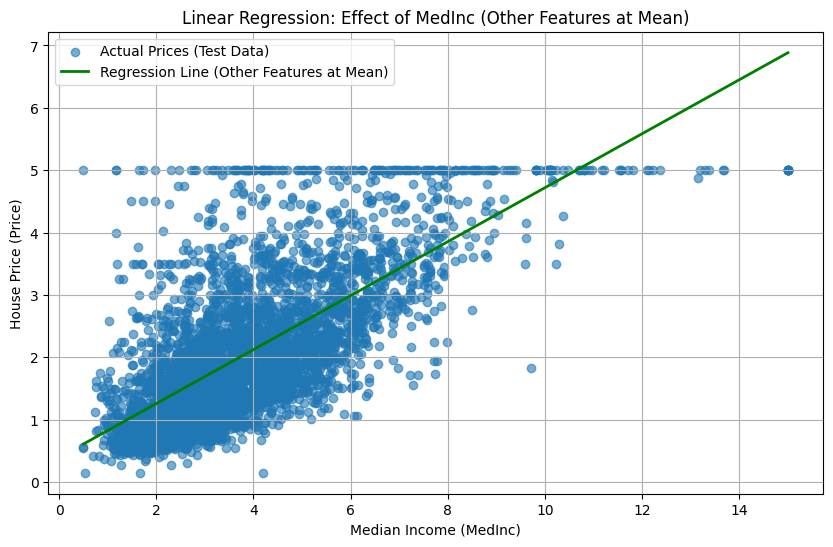

'Here We make all the feature constant except MedeInc so here we can find a single line'

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get the mean of all features in the training set
mean_features = x_train.mean()

# Create a range of MedInc values for plotting
medinc_range = np.linspace(x['MedInc'].min(), x['MedInc'].max(), 100).reshape(-1, 1)

# Create a DataFrame for prediction, filling other features with their mean
# This creates a dummy DataFrame where only MedInc varies across its range
# and all other features are held constant at their mean.
plot_df = pd.DataFrame(mean_features.values.reshape(1, -1), columns=x.columns)
plot_df = pd.concat([plot_df] * len(medinc_range), ignore_index=True)
plot_df['MedInc'] = medinc_range

# Make predictions using the original model on this specially constructed DataFrame
# This will produce a straight line because all other features are constant.
single_feature_y_pred = model.predict(plot_df)

plt.figure(figsize=(10, 6))
plt.scatter(x_test['MedInc'], y_test, alpha=0.6, label='Actual Prices (Test Data)')
plt.plot(medinc_range, single_feature_y_pred, color='green', linewidth=2, label='Regression Line (Other Features at Mean)')
plt.xlabel('Median Income (MedInc)')
plt.ylabel('House Price (Price)')
plt.title('Linear Regression: Effect of MedInc (Other Features at Mean)')
plt.legend()
plt.grid(True)
plt.show()
model.score(x_test,y_test)

"Here We make all the feature constant except MedeInc so here we can find a single line"

x_train: 16512
x_test : 4128
y_train: 16512
y_test : 4128
Prediction: [1.72069275 2.893637   1.88047024 ... 1.35829027 2.11361102 0.94753699]
MSE: 0.5124717232649117
R2 : 0.6055190474770135
Model score: 0.6055190474770135


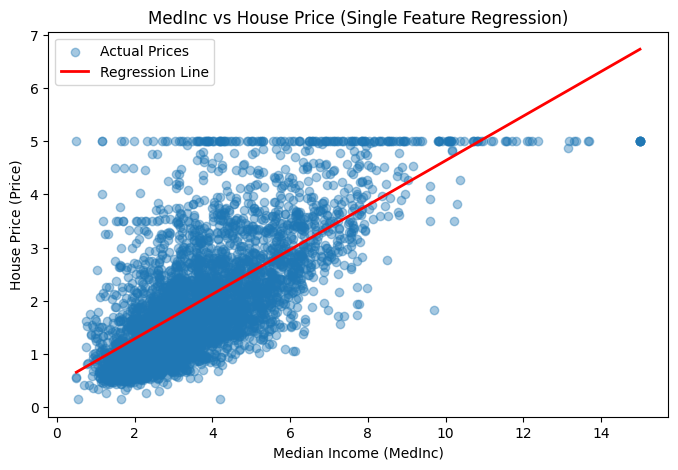

Single-feature R2: 0.46908217998217183


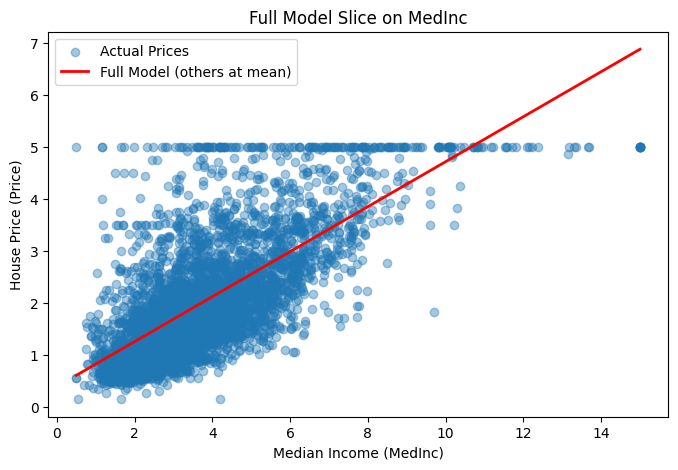

MedInc        0.688075
HouseAge      0.105623
AveRooms      0.151948
AveBedrms    -0.046701
Population   -0.024650
AveOccup     -0.023737
Latitude     -0.144160
Longitude    -0.045967
Price         1.000000
Name: Price, dtype: float64
MedInc        0.684923
HouseAge      0.101470
AveRooms      0.155458
AveBedrms    -0.073076
Population   -0.014121
AveOccup     -0.004534
Latitude     -0.131827
Longitude    -0.057037
dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.datasets import fetch_california_housing

# ---------------------------------------------------------------
# 1. Data load
# ---------------------------------------------------------------
housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns=housing.feature_names)
df['Price'] = housing.target

x = df.drop('Price', axis=1)
y = df['Price']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=50
)
print('x_train:', x_train.shape[0])
print('x_test :', x_test.shape[0])
print('y_train:', y_train.shape[0])
print('y_test :', y_test.shape[0])

# ---------------------------------------------------------------
# 2. Full model (8 ta feature diye)
# ---------------------------------------------------------------
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print('Prediction:', y_pred)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print('MSE:', mse)
print('R2 :', r2)
print('Model score:', model.score(x_test, y_test))

# ---------------------------------------------------------------
# 3. Single line plot (shudhu MedInc diye simple regression)
# ---------------------------------------------------------------
x_single = df[['MedInc']]
xs_train, xs_test, ys_train, ys_test = train_test_split(
    x_single, y, test_size=0.2, random_state=50
)

model_single = LinearRegression()
model_single.fit(xs_train, ys_train)

line_x = pd.DataFrame(
    {'MedInc': np.linspace(xs_test['MedInc'].min(), xs_test['MedInc'].max(), 100)}
)
line_y = model_single.predict(line_x)

plt.figure(figsize=(8, 5))
plt.scatter(xs_test['MedInc'], ys_test, alpha=0.4, label='Actual Prices')
plt.plot(line_x['MedInc'], line_y, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Median Income (MedInc)')
plt.ylabel('House Price (Price)')
plt.title('MedInc vs House Price (Single Feature Regression)')
plt.legend()
plt.show()

print('Single-feature R2:', model_single.score(xs_test, ys_test))

# ---------------------------------------------------------------
# 4. Full model theke MedInc slice (onno feature gulo mean e fixed)
# ---------------------------------------------------------------
mean_vals = x_train.mean()
medinc_range = np.linspace(x_test['MedInc'].min(), x_test['MedInc'].max(), 100)

grid = pd.DataFrame([mean_vals.values] * 100, columns=x_train.columns)
grid['MedInc'] = medinc_range

plt.figure(figsize=(8, 5))
plt.scatter(x_test['MedInc'], y_test, alpha=0.4, label='Actual Prices')
plt.plot(medinc_range, model.predict(grid), color='red', linewidth=2,
         label='Full Model (others at mean)')
plt.xlabel('Median Income (MedInc)')
plt.ylabel('House Price (Price)')
plt.title('Full Model Slice on MedInc')
plt.legend()
plt.show()

# ---------------------------------------------------------------
# 5. Correlation
# ---------------------------------------------------------------
pc = df.corr()['Price']
print(pc)
print(x_test.corrwith(y_test))